# EOSC 410 — Exploratory data analysis: BC wildfires × air quality

Covers data coverage, raw-data figures, the fire–PM2.5 link at different scales, a PCA preview, and weather vs fire.
Put the CSVs in a `data/` folder next to this notebook (or change `D` below). Figures are saved to `figs/` and `raw_figs/`.

In [1]:
import numpy as np, pandas as pd, matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from pathlib import Path

D, F = Path("data"), Path("figs"); F.mkdir(exist_ok=True)
BLUE, ORANGE, AQUA, GRID, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#e1e0d9", "#1f1f1d", "#6b6a64"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 130, "savefig.bbox": "tight", "lines.linewidth": 1.6})
FS = [5, 6, 7, 8, 9]  # fire-season months used throughout

## Load

In [2]:
meta = pd.read_csv(D/"station_metadata.csv", dtype={"station_id": str})
meta["label"] = meta.city
lab = dict(zip(meta.station_id, meta.label))
V = {"PM2.5": "daily_pm25.csv", "O3": "daily_o3.csv", "NO2": "daily_no2.csv", "Temp": "daily_temp_c.csv",
     "RH": "daily_rh_pct.csv", "Wind spd": "daily_wind_speed_ms.csv", "Wind dir": "daily_wind_direction_deg.csv"}
dd = {k: pd.read_csv(D/f, index_col=0, parse_dates=True) for k, f in V.items()}
pm = dd["PM2.5"]
fires = pd.read_csv(D/"historical_fires.csv", parse_dates=["fire_start_date"])
f = fires[(fires.fire_start_date >= "2009-11-01") & (fires.fire_start_date < "2025-01-01")].copy()

## Fig 1: coverage

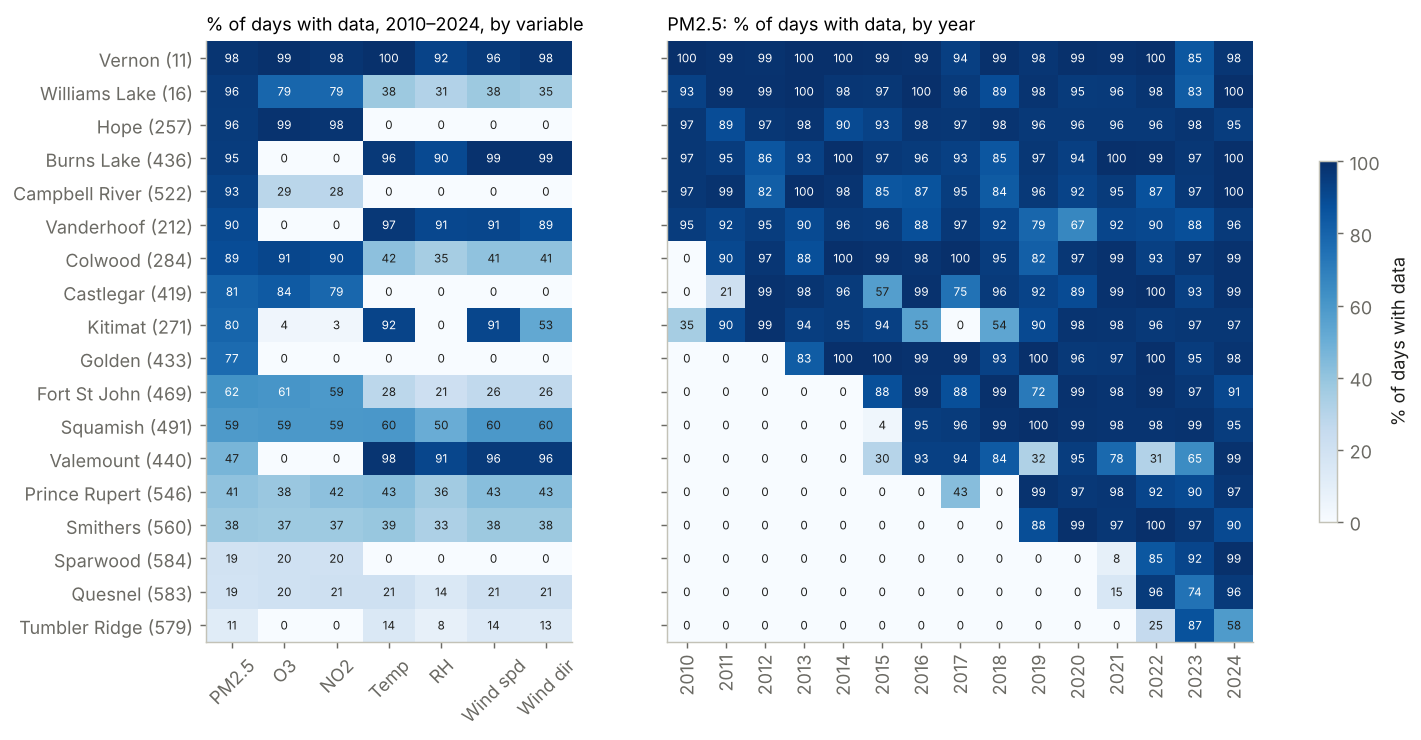

In [3]:
cov = pd.DataFrame({k: v.notna().mean()*100 for k, v in dd.items()}).reindex(meta.station_id)
order = cov["PM2.5"].sort_values(ascending=False).index
yr = pm.groupby(pm.index.year).apply(lambda x: x.notna().mean()*100).T.reindex(order)
fig, ax = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [1, 1.6]})
for a, M, title in [(ax[0], cov.reindex(order), "% of days with data, 2010–2024, by variable"),
                    (ax[1], yr, "PM2.5: % of days with data, by year")]:
    im = a.imshow(M.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    a.set_xticks(range(M.shape[1]), M.columns, rotation=45 if M is not yr else 90)
    a.set_yticks(range(M.shape[0]), [f"{lab[s]} ({s})" for s in M.index] if M is not yr else []); a.grid(False)
    a.set_title(title, loc="left", fontsize=10)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]
            a.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=6.5, color="white" if v > 60 else INK)
fig.colorbar(im, ax=ax, shrink=0.6, label="% of days with data")
fig.savefig(F/"01_coverage.png"); plt.show()

## Fig 2: map

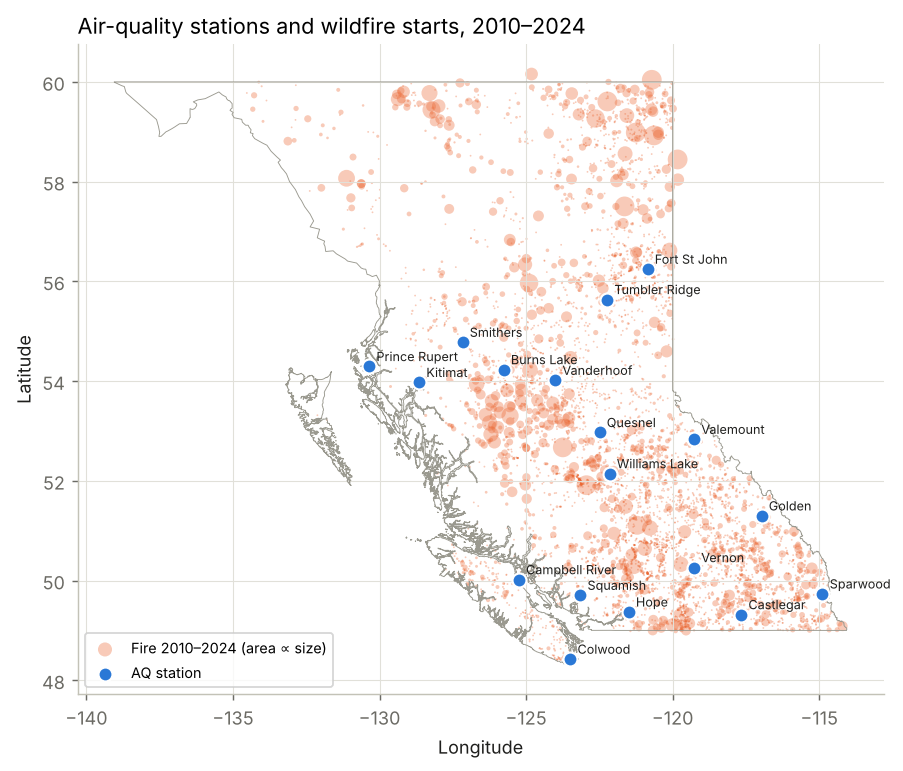

In [4]:
f1024 = f[f.fire_start_date >= "2010"]
fig, ax = plt.subplots(figsize=(8, 8))
try:
    b = pd.read_csv(D/"bc_boundary_points.csv")
    for _, p in b.sort_values(["polygon_id", "point_order"]).groupby("polygon_id"):
        ax.plot(p.longitude, p.latitude, color="#9a998f", lw=0.5)
except FileNotFoundError:
    pass
ax.scatter(f1024.lon, f1024.lat, s=np.clip(np.sqrt(f1024["size"])/4, 1, 120), color=ORANGE, alpha=0.35,
           edgecolor="none", label="Fire 2010–2024 (area ∝ size)")
ax.scatter(meta.longitude, meta.latitude, s=60, color=BLUE, edgecolor="white", lw=1.2, zorder=3, label="AQ station")
for _, r in meta.iterrows():
    ax.annotate(r.label, (r.longitude, r.latitude), xytext=(4, 3), textcoords="offset points", fontsize=7, color=INK)
ax.set_aspect(1/np.cos(np.radians(54))); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Air-quality stations and wildfire starts, 2010–2024", loc="left"); ax.legend(loc="lower left", fontsize=8)
fig.savefig(F/"02_map.png"); plt.show()

## Fig 3: time series (two panels, no dual axis)

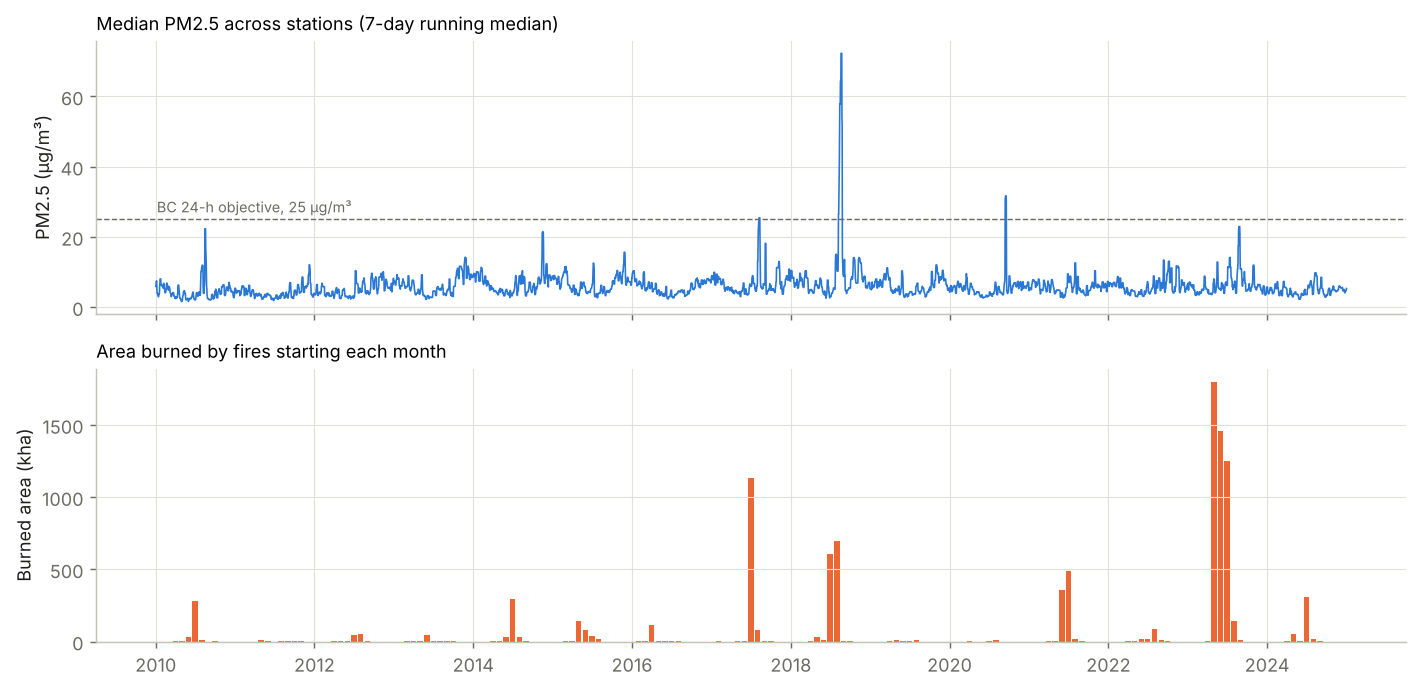

In [5]:
med = pm.median(axis=1).rolling(7, center=True, min_periods=3).median()
mon_area = f1024.set_index("fire_start_date")["size"].resample("MS").sum()/1e3
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ax[0].plot(med.index, med, color=BLUE, lw=0.9)
ax[0].axhline(25, color=MUTED, ls="--", lw=0.8); ax[0].text(med.index[5], 27, "BC 24-h objective, 25 µg/m³", fontsize=8, color=MUTED)
ax[0].set_ylabel("PM2.5 (µg/m³)"); ax[0].set_title("Median PM2.5 across stations (7-day running median)", loc="left", fontsize=10)
ax[1].bar(mon_area.index, mon_area.values, width=25, color=ORANGE)
ax[1].set_ylabel("Burned area (kha)"); ax[1].set_title("Area burned by fires starting each month", loc="left", fontsize=10)
fig.savefig(F/"03_timeseries.png"); plt.show()

## Distance / window features

Pooled within-station Spearman rho, PM2.5 vs nearby burned area (May–Sep):
         7     14    30    60
100   0.20  0.23  0.24  0.24
200   0.27  0.26  0.27  0.26
300   0.29  0.27  0.29  0.28
500   0.31  0.29  0.31  0.30
1000  0.29  0.27  0.29  0.27


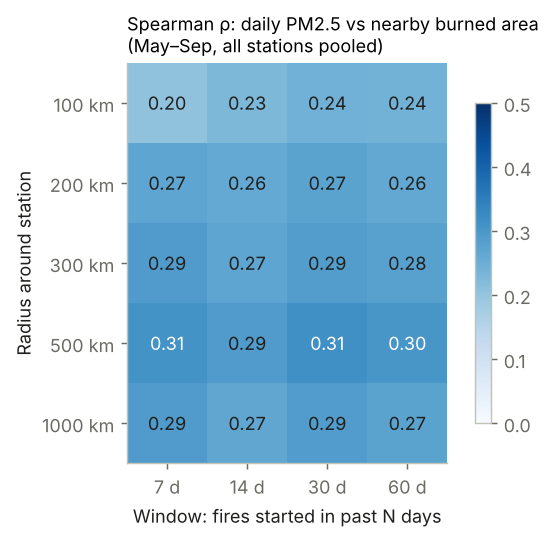

Best setting: 500 km / 30 d. Per-station rho:
 Prince Rupert     0.06
Colwood           0.07
Campbell River    0.13
Kitimat           0.21
Smithers          0.22
Vanderhoof        0.24
Burns Lake        0.26
Hope              0.31
Fort St John      0.37
Tumbler Ridge     0.39
Squamish          0.39
Valemount         0.40
Williams Lake     0.40
Vernon            0.44
Quesnel           0.48
Castlegar         0.48
Golden            0.55
Sparwood          0.63
dtype: float64


In [6]:
def hav(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2); dl = np.radians(lon2-lon1)
    a = np.sin((p2-p1)/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 6371*2*np.arcsin(np.sqrt(a))

days = pd.date_range("2009-11-01", "2024-12-31")
def nearby(sid, R, W):
    r = meta.set_index("station_id").loc[sid]
    d = hav(r.latitude, r.longitude, f.lat.values, f.lon.values)
    s = f[d <= R].groupby("fire_start_date")["size"].sum().reindex(days, fill_value=0)
    return s.rolling(W, min_periods=1).sum().loc["2010":]

radii, wins = [100, 200, 300, 500, 1000], [7, 14, 30, 60]
fsmask = pm.index.month.isin(FS)
grid = pd.DataFrame(index=radii, columns=wins, dtype=float)
for R in radii:
    for W in wins:
        xs, ys = [], []
        for sid in pm.columns:
            x = nearby(sid, R, W); y = pm[sid]
            ok = fsmask & y.notna()
            # rank within station to remove baseline differences
            xs.append(x[ok].rank(pct=True)); ys.append(y[ok].rank(pct=True))
        grid.loc[R, W] = spearmanr(pd.concat(xs), pd.concat(ys))[0]
print("Pooled within-station Spearman rho, PM2.5 vs nearby burned area (May–Sep):\n", grid.round(2))
fig, ax = plt.subplots(figsize=(5.5, 4))
im = ax.imshow(grid.values.astype(float), cmap="Blues", vmin=0, vmax=max(0.5, grid.values.max()))
ax.set_xticks(range(len(wins)), [f"{w} d" for w in wins]); ax.set_yticks(range(len(radii)), [f"{r} km" for r in radii])
ax.set_xlabel("Window: fires started in past N days"); ax.set_ylabel("Radius around station"); ax.grid(False)
for i in range(len(radii)):
    for j in range(len(wins)):
        v = grid.values[i, j]; ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.3 else INK)
ax.set_title("Spearman ρ: daily PM2.5 vs nearby burned area\n(May–Sep, all stations pooled)", loc="left", fontsize=10)
fig.colorbar(im, shrink=0.8); fig.savefig(F/"04_radius_window.png"); plt.show()

# per-station rho at best setting
Rb, Wb = grid.stack().astype(float).idxmax()
st = {}
for sid in pm.columns:
    x = nearby(sid, Rb, Wb); y = pm[sid]; ok = fsmask & y.notna()
    if ok.sum() > 100: st[sid] = spearmanr(x[ok], y[ok])[0]
st = pd.Series(st).sort_values()
print(f"Best setting: {Rb} km / {Wb} d. Per-station rho:\n", st.rename(index=lab).round(2))

## Fig 5: annual (the n=15 problem)


Annual table:
       area_kha  median_station_FS_mean  smoke_days
2010     322.1                     4.7         3.5
2011      13.0                     3.4         0.0
2012     100.6                     5.3         0.0
2013      58.0                     4.6         0.0
2014     363.3                     5.8         2.0
2015     283.6                     6.0         2.0
2016     121.9                     4.4         0.0
2017    1222.4                    11.5        15.0
2018    1350.8                    15.8        16.0
2019      21.8                     4.9         0.0
2020      17.6                     6.5         5.0
2021     860.3                     6.7         5.0
2022     132.0                     6.7         2.0
2023    4663.6                    13.7        17.0
2024     381.3                     6.4         2.0
Annual Spearman area vs FS-mean PM2.5: 0.73 | vs smoke days: 0.76


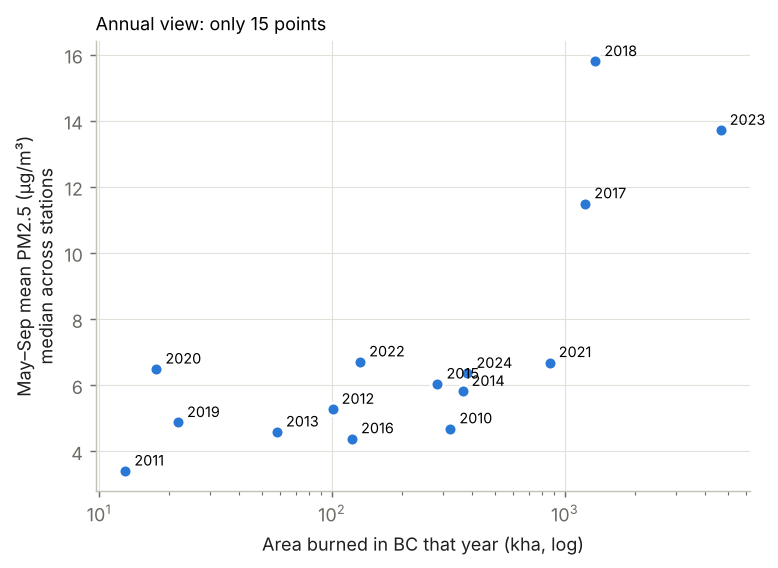

In [7]:
ann_area = f1024.groupby(f1024.fire_start_date.dt.year)["size"].sum()/1e3
pmfs = pm[fsmask]
ann = pd.DataFrame({"area_kha": ann_area,
                    "median_station_FS_mean": pmfs.groupby(pmfs.index.year).mean().median(axis=1),
                    "smoke_days": (pmfs > 25).groupby(pmfs.index.year).sum().where(
                        pmfs.notna().groupby(pmfs.index.year).sum() > 100).median(axis=1)})
print("\nAnnual table:\n", ann.round(1))
print("Annual Spearman area vs FS-mean PM2.5:", round(spearmanr(ann.area_kha, ann.median_station_FS_mean)[0], 2),
      "| vs smoke days:", round(spearmanr(ann.area_kha, ann.smoke_days)[0], 2))
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(ann.area_kha, ann.median_station_FS_mean, s=50, color=BLUE, edgecolor="white", lw=1.5, zorder=3)
for y, r in ann.iterrows(): ax.annotate(str(y), (r.area_kha, r.median_station_FS_mean), xytext=(5, 3), textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("Area burned in BC that year (kha, log)"); ax.set_ylabel("May–Sep mean PM2.5 (µg/m³)\nmedian across stations")
ax.set_title("Annual view: only 15 points", loc="left", fontsize=10); fig.savefig(F/"05_annual.png"); plt.show()

## Fig 6: PCA feasibility


PCA: 11 stations, 932 complete fire-season days (2016–2024). Var expl: [54.1 12.  10.5  5.8  4.5]
                 PC1   PC2   PC3
Squamish        0.34 -0.23 -0.16
Fort St John    0.23  0.55 -0.15
Vanderhoof      0.31  0.35 -0.16
Vernon          0.35 -0.06  0.33
Williams Lake   0.32  0.12  0.21
Golden          0.33  0.04  0.46
Castlegar       0.34 -0.10  0.35
Campbell River  0.21 -0.45 -0.22
Colwood         0.26 -0.31 -0.45
Hope            0.33 -0.21 -0.14
Burns Lake      0.25  0.38 -0.41


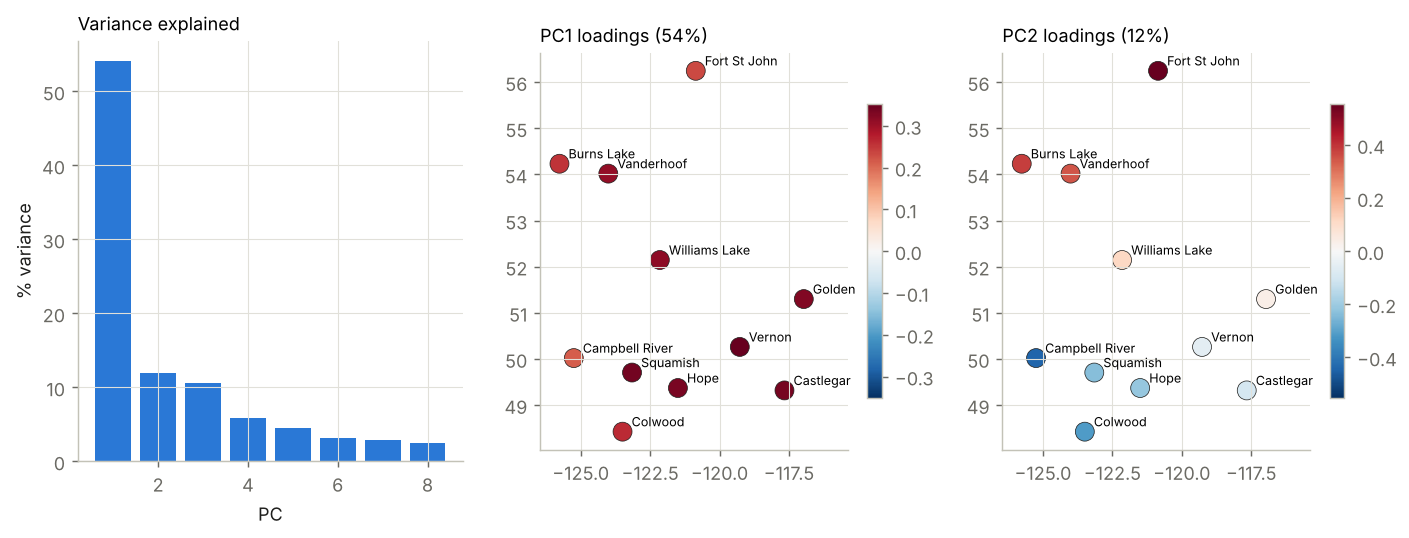

Spearman PC1 vs province 30-d burned area: 0.54


In [8]:
keep = cov.index[(pm.loc["2016":].notna().mean() > 0.85).reindex(cov.index)].tolist()
def fill_short_gaps(col, max_gap=3):
    # interpolate gaps of <= max_gap days only; longer gaps stay empty
    missing = col.isna(); gap_len = missing.groupby((~missing).cumsum()).transform("sum")
    return col.interpolate(limit_area="inside").where(~(missing & (gap_len > max_gap)))
X = pm.loc["2016":, keep].apply(fill_short_gaps)
X = X[X.index.month.isin(FS)].dropna()
Z = np.log1p(X); Z = (Z-Z.mean())/Z.std()
pca = PCA().fit(Z); pcs = pd.DataFrame(pca.transform(Z)[:, :3], index=Z.index, columns=["PC1", "PC2", "PC3"])
ld = pd.DataFrame(pca.components_[:3].T, index=keep, columns=["PC1", "PC2", "PC3"])
print(f"\nPCA: {len(keep)} stations, {len(Z)} complete fire-season days (2016–2024). Var expl:", (pca.explained_variance_ratio_[:5]*100).round(1))
print(ld.rename(index=lab).round(2))
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2))
ax[0].bar(range(1, 9), pca.explained_variance_ratio_[:8]*100, color=BLUE); ax[0].set_xlabel("PC"); ax[0].set_ylabel("% variance")
ax[0].set_title("Variance explained", loc="left", fontsize=10)
mm = meta.set_index("station_id").loc[keep]
for a, pc in zip(ax[1:], ["PC1", "PC2"]):
    v = ld[pc]; lim = np.abs(v).max()
    sc = a.scatter(mm.longitude, mm.latitude, c=v, cmap="RdBu_r", vmin=-lim, vmax=lim, s=110, edgecolor=INK, lw=0.4)
    for s, r in mm.iterrows(): a.annotate(lab[s], (r.longitude, r.latitude), xytext=(5, 3), textcoords="offset points", fontsize=7)
    a.set_title(f"{pc} loadings ({pca.explained_variance_ratio_[int(pc[-1])-1]*100:.0f}%)", loc="left", fontsize=10)
    a.set_xlim(mm.longitude.min()-0.7, mm.longitude.max()+1.6); a.set_aspect(1/np.cos(np.radians(53))); fig.colorbar(sc, ax=a, shrink=0.7)
fig.savefig(F/"06_pca_preview.png"); plt.show()
# PC1 vs province burned area (30-day)
prov = f.groupby("fire_start_date")["size"].sum().reindex(days, fill_value=0).rolling(30, min_periods=1).sum()
print("Spearman PC1 vs province 30-d burned area:", round(spearmanr(pcs.PC1, prov.reindex(pcs.index))[0], 2))

## Fig 7: weather vs fire (RQ idea 2)


Weather stations used: ['Vernon', 'Vanderhoof', 'Burns Lake', 'Valemount']; monthly May–Sep n=70
Spearman monthly: T~area 0.69 | RH~area -0.58 | T~count 0.71 | RH~count -0.65
Spearman with monthly anomalies: T~area 0.4 | RH~area -0.48


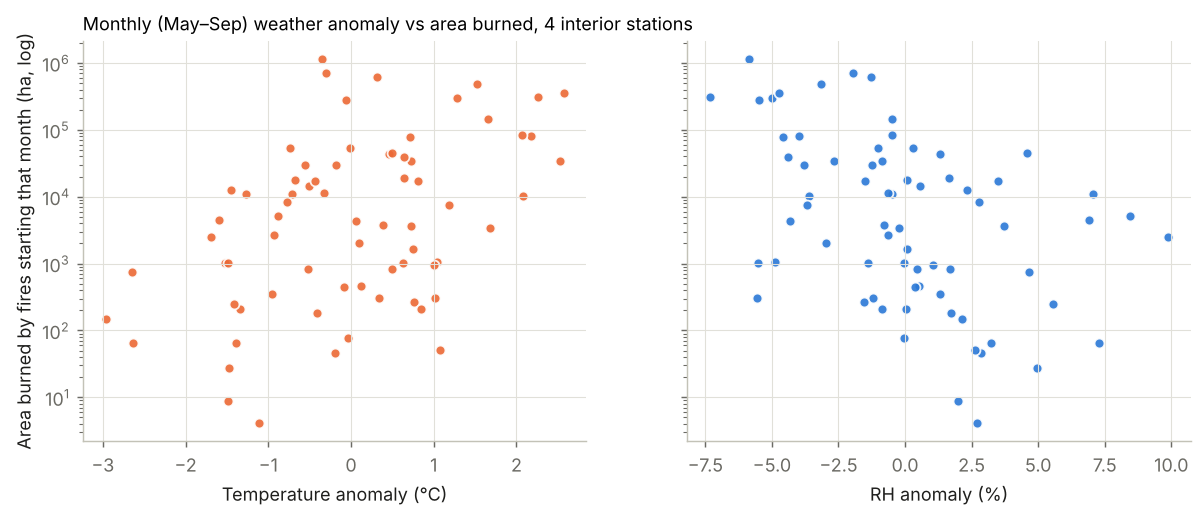

done


In [9]:
met = [s for s in dd["Temp"].columns if dd["Temp"][s].notna().mean() > 0.85 and dd["RH"][s].notna().mean() > 0.85]
T = dd["Temp"][met].mean(axis=1).resample("MS").mean(); H = dd["RH"][met].mean(axis=1).resample("MS").mean()
A = f1024.set_index("fire_start_date")["size"].resample("MS").sum()
N = f1024.set_index("fire_start_date")["size"].resample("MS").count()
m = pd.DataFrame({"T": T, "RH": H, "area": A, "n": N}).dropna(); m = m[m.index.month.isin(FS)]
print(f"\nWeather stations used: {[lab[s] for s in met]}; monthly May–Sep n={len(m)}")
print("Spearman monthly: T~area", round(spearmanr(m["T"], m.area)[0], 2), "| RH~area", round(spearmanr(m.RH, m.area)[0], 2),
      "| T~count", round(spearmanr(m["T"], m.n)[0], 2), "| RH~count", round(spearmanr(m.RH, m.n)[0], 2))
# anomalies (remove seasonal cycle) - the fairer test
an = m.copy()
for c in ["T", "RH"]: an[c] = m[c] - m.groupby(m.index.month)[c].transform("mean")
print("Spearman with monthly anomalies: T~area", round(spearmanr(an["T"], an.area)[0], 2), "| RH~area", round(spearmanr(an.RH, an.area)[0], 2))
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, c, xl, col in [(ax[0], "T", "Temperature anomaly (°C)", ORANGE), (ax[1], "RH", "RH anomaly (%)", BLUE)]:
    a.scatter(an[c], an.area.clip(lower=1), s=30, color=col, edgecolor="white", lw=1, alpha=0.9)
    a.set_yscale("log"); a.set_xlabel(xl)
ax[0].set_ylabel("Area burned by fires starting that month (ha, log)")
ax[0].set_title(f"Monthly (May–Sep) weather anomaly vs area burned, {len(met)} interior stations", loc="left", fontsize=10)
fig.savefig(F/"07_weather_vs_fire.png"); plt.show()
print("done")

## Precipitation and pressure coverage
Both variables are nearly empty, so they are excluded from the analysis.

In [10]:
for v in ["daily_precip_mm.csv", "daily_pressure.csv"]:
    d = pd.read_csv(D/v, index_col=0, parse_dates=True)
    c = (d.notna().mean() * 100).round(1)
    print(f"{v}: stations with any data -> {({lab[k]: x for k, x in c[c > 0].items()})}")
    print("   overall share of station-days with data:", f"{d.notna().values.mean():.1%}")

daily_precip_mm.csv: stations with any data -> {'Williams Lake': 35.6, 'Tumbler Ridge': 14.1}
   overall share of station-days with data: 2.8%
daily_pressure.csv: stations with any data -> {'Vanderhoof': 3.3, 'Prince Rupert': 2.9}
   overall share of station-days with data: 0.3%


## Raw-data figures for the report
One figure per dataset, for the Data description section.

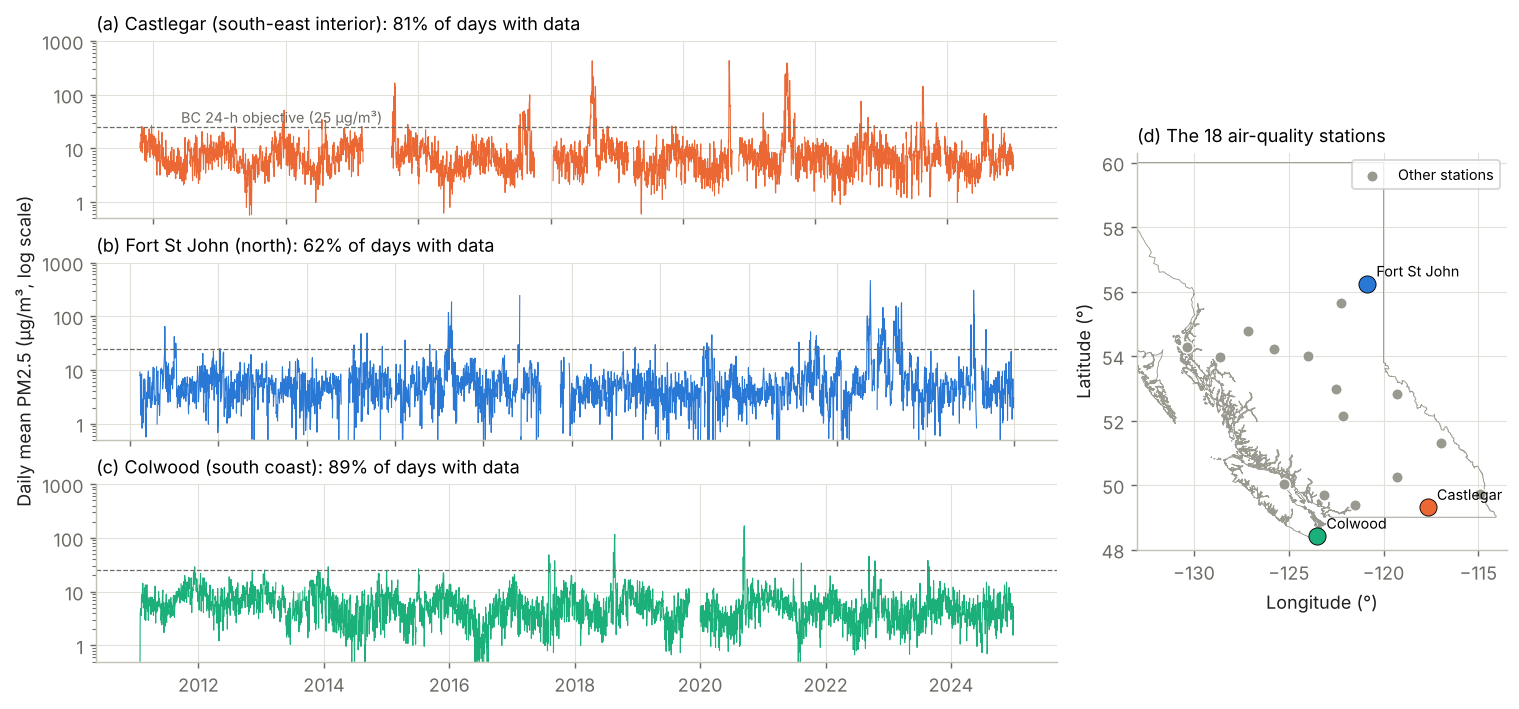

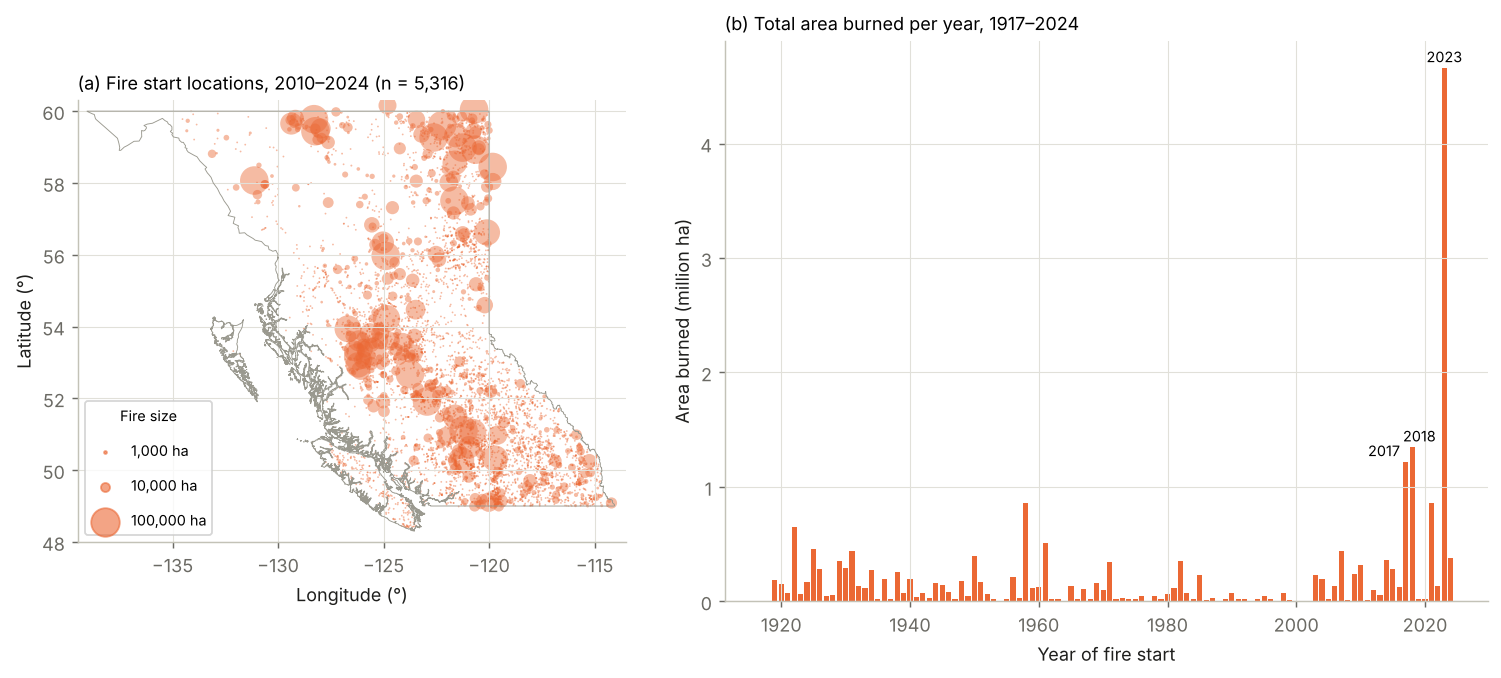

max annual 2023 4.66 | 2017 1.22 2018 1.35 | fires in 2025-26 excluded: 316 | largest fire ha 768915


In [11]:
b = pd.read_csv(D/"bc_boundary_points.csv")
OUT = Path("raw_figs"); OUT.mkdir(exist_ok=True)
ORANGE, AQUA = "#eb6834", "#1baf7a"
meta_i = meta.set_index("station_id")
def bc(ax):
    for _, p in b.sort_values(["polygon_id", "point_order"]).groupby("polygon_id"):
        ax.plot(p.longitude, p.latitude, color="#9a998f", lw=.5)
    ax.set_aspect(1/np.cos(np.radians(54))); ax.set_xlim(-139.5, -113.5); ax.set_ylim(48, 60.3)
    ax.set_xlabel("Longitude (°)"); ax.set_ylabel("Latitude (°)")
# ---------- Air quality ----------
ex = {"419": ("Castlegar (south-east interior)", ORANGE), "469": ("Fort St John (north)", BLUE), "284": ("Colwood (south coast)", AQUA)}
fig = plt.figure(figsize=(14, 6.2))
gs = fig.add_gridspec(len(ex), 2, width_ratios=[2.6, 1], wspace=0.12, hspace=0.25)
for k, (sid, (lbl, col)) in enumerate(ex.items()):
    ax = fig.add_subplot(gs[k, 0]); s = pm[sid]
    ax.plot(s.index, s, color=col, lw=.6)
    ax.set_yscale("log"); ax.set_ylim(0.5, 1000); ax.set_yticks([1, 10, 100, 1000], ["1", "10", "100", "1000"])
    ax.axhline(25, color="#6b6a64", ls="--", lw=.7)
    ax.set_title(f"({'abc'[k]}) {lbl}: {s.notna().mean():.0%} of days with data", loc="left", fontsize=10)
    if k == 1: ax.set_ylabel("Daily mean PM2.5 (µg/m³, log scale)")
    if k < len(ex) - 1: ax.tick_params(labelbottom=False)
fig.axes[0].text(pd.Timestamp("2012-06-01"), 30, "BC 24-h objective (25 µg/m³)", fontsize=8, color="#6b6a64")
ax = fig.add_subplot(gs[:, 1]); bc(ax)
ax.set_xlim(-133, -113.5)
ax.scatter(meta_i.longitude, meta_i.latitude, s=40, color="#9a998f", edgecolor="white", lw=.8, zorder=3, label="Other stations")
for sid, (lbl, col) in ex.items():
    r = meta_i.loc[sid]; ax.scatter(r.longitude, r.latitude, s=90, color=col, edgecolor="k", lw=.5, zorder=4)
    ax.annotate(lbl.split(" (")[0], (r.longitude, r.latitude), xytext=(5, 4), textcoords="offset points", fontsize=8)
ax.set_title(f"(d) The {len(meta_i)} air-quality stations", loc="left", fontsize=10); ax.legend(loc="upper right", fontsize=8)
fig.savefig(OUT/"raw_air_quality.png", dpi=200, bbox_inches="tight"); plt.show()

# ---------- Fires ----------
f = fires.copy(); f["year"] = f.fire_start_date.dt.year
fig = plt.figure(figsize=(14, 5.6))
gs = fig.add_gridspec(1, 2, width_ratios=[1.15, 1.6], wspace=0.15)
ax = fig.add_subplot(gs[0]); bc(ax)
f2 = f[(f.year >= 2010) & (f.year <= 2024)].sort_values("size", ascending=False)
ax.scatter(f2.lon, f2.lat, s=np.clip(f2["size"] / 400, 1, 250), color=ORANGE, alpha=.45, edgecolor="none")
for ha in [1_000, 10_000, 100_000]:
    ax.scatter([], [], s=np.clip(ha / 400, 1, 250), color=ORANGE, alpha=.6, label=f"{ha:,} ha")
ax.legend(title="Fire size", loc="lower left", fontsize=8, title_fontsize=8, labelspacing=1.2)
ax.set_title(f"(a) Fire start locations, 2010–2024 (n = {len(f2):,})", loc="left", fontsize=10)
ax = fig.add_subplot(gs[1])
ann = f.groupby("year")["size"].sum().reindex(range(f.year.min(), 2025), fill_value=0) / 1e6
ax.bar(ann.index, ann.values, width=.8, color=ORANGE)
ax.set_ylabel("Area burned (million ha)"); ax.set_xlabel("Year of fire start")
for y, dx in [(2017, -12), (2018, 4), (2023, 0)]:
    ax.annotate(str(y), (y, ann[y]), xytext=(dx, 3), textcoords="offset points", ha="center", fontsize=8)
ax.set_title(f"(b) Total area burned per year, {f.year.min()}–2024", loc="left", fontsize=10)
fig.savefig(OUT/"raw_fires.png", dpi=200, bbox_inches="tight"); plt.show()
print("max annual", ann.idxmax(), round(ann.max(), 2), "| 2017", round(ann[2017], 2), "2018", round(ann[2018], 2),
      "| fires in 2025-26 excluded:", int((f.year > 2024).sum()), "| largest fire ha", int(f["size"].max()))